# Image denoising with DFT matrices on CIM

Use a discrete Fourier transform (DFT), a low-pass frequency mask, and an inverse DFT to denoise a real grayscale photograph. No neural network or training is involved. Compare NumPy's FFT implementation with real matrix operations mapped onto MemFast arrays, first with ideal devices and then with write variation of 0.02.

The executed results and full-size figure are retained below. Install MemFast in this Python environment, plus `numpy`, `Pillow`, `matplotlib`, and a Jupyter frontend to rerun the notebook. The lake landscape is included in `assets/lake_landscape.png`; no image download is needed. Run all cells in order. The image is 256 x 256; CUDA is selected when available, with CPU as the fallback.

In [1]:
%matplotlib inline
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

from memfast import Config, Nonidealities, Simulator

DEVICE = os.environ.get("MEMFAST_NOTEBOOK_DEVICE", "cuda:0" if torch.cuda.is_available() else "cpu")
SIZE = 256
SEED = 135
NOISE_STD = 0.22  # About 56 gray levels out of 255, before clipping.
CUTOFF = 0.12  # Gaussian frequency width, in cycles per pixel.
print(f"Device: {DEVICE}; image: {SIZE} x {SIZE}")

Device: cuda:0; image: 256 x 256


## 1. Load the photograph and add noise

Load the bundled lake landscape, convert it to grayscale and resize it before adding Gaussian noise with a fixed seed. The noise has standard deviation 0.22 before clipping noisy pixels to [0, 1]. This resized photograph is the clean target for every PSNR calculation; it is never an input to the denoiser.

Image: [Lake Mapourika](https://commons.wikimedia.org/wiki/File:Lake_Mapourika1.jpg), Paul Stewart, [CC0 1.0](https://creativecommons.org/publicdomain/zero/1.0/). The bundled image is a square crop resized from the original photograph.

In [2]:
notebook_dir = Path.cwd()
if not (notebook_dir / "03_dft_image_denoising.ipynb").is_file():
    notebook_dir = notebook_dir / "examples" / "notebooks"
sample_path = notebook_dir / "assets" / "lake_landscape.png"
with Image.open(sample_path) as photograph:
    grayscale = photograph.convert("L").resize((SIZE, SIZE), resample=Image.Resampling.LANCZOS)
    clean = np.asarray(grayscale, dtype=np.float64) / 255.0
rng = np.random.default_rng(SEED)
noisy = np.clip(clean + rng.normal(0.0, NOISE_STD, clean.shape), 0.0, 1.0)
assert clean.shape == noisy.shape == (SIZE, SIZE)
assert np.isfinite(clean).all() and np.isfinite(noisy).all()
print(f"Clean range: [{clean.min():.3f}, {clean.max():.3f}]")

Clean range: [0.000, 1.000]


## 2. Define the normalized DFT and the frequency mask

For an $N \times N$ image $X$, define the unitary DFT matrix

$$F_{k,n} = \frac{1}{\sqrt{N}}\exp\left(-2\pi i\frac{kn}{N}\right).$$

The two-dimensional transform and inverse are

$$Y = F X F^T, \qquad \widehat{X} = F^H (M \odot Y)\,\overline{F}.$$

Here $T$ means transpose, $H$ means conjugate transpose, and the bar means complex conjugation. Each axis uses the $1/\sqrt{N}$ normalization, matching NumPy's `norm='ortho'` in both directions.

Use a smooth Gaussian low-pass response

$$M(f_y,f_x)=\exp\left[-\frac{f_y^2+f_x^2}{2c^2}\right],\qquad c=0.12\ \text{cycles/pixel}.$$

This fixed response suppresses high-frequency noise while avoiding the ringing of a hard cutoff. Its approximate spatial standard deviation is $1/(2\pi c)=1.33$ pixels. The image size, noise level, seed, and filter width are fixed above; there is no parameter search against the clean target. The mask uses unshifted `fftfreq` order, so DC is at index (0, 0); `fftshift` is used only when displaying the mask. Low-pass filtering still blurs some texture and cannot recover lost detail.

In [3]:
indices = np.arange(SIZE)
F = np.exp(-2j * np.pi * np.outer(indices, indices) / SIZE) / np.sqrt(SIZE)
frequencies = np.fft.fftfreq(SIZE)
radius = np.hypot(frequencies[:, None], frequencies[None, :])
mask = np.exp(-0.5 * (radius / CUTOFF) ** 2)

numpy_spectrum = np.fft.fft2(noisy, norm="ortho")
numpy_inverse = np.fft.ifft2(mask * numpy_spectrum, norm="ortho")
standard = np.clip(numpy_inverse.real, 0.0, 1.0)

# Verify signs, normalization, both axes, and the inverse independently.
np.testing.assert_allclose(F @ noisy @ F.T, numpy_spectrum, atol=1e-12, rtol=1e-12)
np.testing.assert_allclose(F.conj().T @ numpy_spectrum @ F.conj(), noisy, atol=1e-12, rtol=1e-12)
assert mask[0, 0] == 1.0 and np.all((mask > 0) & (mask <= 1))
print(f"Gaussian filter width: {CUTOFF:.2f} cycles/pixel")
print(f"Approximate spatial smoothing width: {1 / (2 * np.pi * CUTOFF):.2f} pixels")
print(f"White-noise variance fraction passed: {np.mean(mask**2):.4f}")
print(f"NumPy inverse imaginary RMS: {np.sqrt(np.mean(numpy_inverse.imag**2)):.3e}")

Gaussian filter width: 0.12 cycles/pixel
Approximate spatial smoothing width: 1.33 pixels
White-noise variance fraction passed: 0.0452
NumPy inverse imaginary RMS: 2.935e-17


## 3. Set ideal and write-variation configurations

Both runs use signed 8-bit inputs and weights, binary slices, 64 x 64 arrays, and 8-bit ADCs. A 256 x 256 DFT matrix spans multiple arrays: each ADC converts at most 64 rows, then digital accumulation restores the scale of each partial sum. Each binary-slice count lies within the ADC's 0..255 range for ideal devices. Weight scales are per output channel and input scales are per input vector.

**Ideal devices still quantize.** Compare them with a dequantized matrix-product oracle, not with an assumption of exact floating-point DFT output. `Nonidealities()` currently defaults to write variation of 0.02, so the ideal case explicitly sets it to zero. The second case enables only write variation of 0.02; read variation and other nonidealities remain zero. The seed and matrix creation order make programming reproducible.

In [4]:
common = dict(
    activation_bits=8,
    weight_bits=8,
    input_slice=(1,) * 8,
    weight_slice=(1,) * 8,
    array_size=(64, 64),
    adc_bits=8,
    input_quant_gran=(1, None),
    weight_quant_gran=(None, 1),
    seed=SEED,
)
ideal_config = Config(**common, nonidealities=Nonidealities(write_variation=0.0))
write_config = Config(**common, nonidealities=Nonidealities(write_variation=0.02))
print("Ideal:", ideal_config.nonidealities)
print("Write 0.02:", write_config.nonidealities)

Ideal: Nonidealities(write_variation=0.0, read_variation=0.0, read_mode='shared', voltage_variation=0.0, adc_nonlinearity=0.0, stuck_at_low=0.0, stuck_at_high=0.0, drift_coefficient=0.0, drift_time=0.0, drift_reference_time=1.0)
Write 0.02: Nonidealities(write_variation=0.02, read_variation=0.0, read_mode='shared', voltage_variation=0.0, adc_nonlinearity=0.0, stuck_at_low=0.0, stuck_at_high=0.0, drift_coefficient=0.0, drift_time=0.0, drift_reference_time=1.0)


## 4. Express complex transforms as real matrix multiplications

For a complex right-hand matrix $B=C+iD$ and row vectors $z=a+ib$,

$$zB=(aC-bD)+i(aD+bC).$$

Use `simulator.matmul(A, B)` with the same operand order as `torch.matmul`.
No programming call or matrix name is required: the simulator manages its
programmed weights internally. Move the selected image axis to the last
dimension so each row is one transform input.

The DFT matrix is symmetric. The right-hand matrix for a forward axis transform
is therefore $F^T=F$, and for an inverse axis transform it is
$\overline F$. All forward and inverse products below pass through MemFast.
Complex assembly, frequency masking, axis movement and clipping are digital;
NumPy FFT appears only in the reference.

In [5]:
def complex_weights(basis, device):
    real = torch.tensor(basis.real, dtype=torch.float32, device=device)
    imag = torch.tensor(basis.imag, dtype=torch.float32, device=device)
    return real, imag


def transform_axis(values, weights, axis, simulator):
    real_weight, imag_weight = weights
    real = values.real.movedim(axis, -1).contiguous()
    imag = values.imag.movedim(axis, -1).contiguous()
    transformed = torch.complex(
        simulator.matmul(real, real_weight) - simulator.matmul(imag, imag_weight),
        simulator.matmul(imag, real_weight) + simulator.matmul(real, imag_weight),
    )
    return transformed.movedim(-1, axis)


@torch.no_grad()
def cim_denoise(image, frequency_mask, config, device="cpu"):
    image = np.asarray(image, dtype=np.float64)
    assert image.ndim == 2 and image.shape[0] == image.shape[1]
    assert frequency_mask.shape == image.shape
    assert np.isfinite(image).all() and np.isfinite(frequency_mask).all()
    n = image.shape[0]
    coordinates = np.arange(n)
    basis = np.exp(-2j * np.pi * np.outer(coordinates, coordinates) / n) / np.sqrt(n)
    simulator = Simulator(config, device=device)
    forward_weights = complex_weights(basis, simulator.device)
    inverse_weights = complex_weights(basis.conj(), simulator.device)
    pixels = torch.tensor(image, dtype=torch.float32, device=simulator.device)
    values = torch.complex(pixels, torch.zeros_like(pixels))
    spectrum = transform_axis(
        transform_axis(values, forward_weights, axis=1, simulator=simulator),
        forward_weights,
        axis=0,
        simulator=simulator,
    )
    filtered = spectrum * torch.tensor(frequency_mask, dtype=torch.float32, device=simulator.device)
    restored = transform_axis(
        transform_axis(filtered, inverse_weights, axis=1, simulator=simulator),
        inverse_weights,
        axis=0,
        simulator=simulator,
    )
    return spectrum.cpu().numpy(), restored.cpu().numpy()

## 5. Check the mapping and compare PSNR

The ideal-device check below quantizes and dequantizes signed test vectors and one real DFT matrix, then compares their digital product with a CIM read.

For pixels in [0, 1], $\mathrm{PSNR}=10\log_{10}(1/\mathrm{MSE})$, with MSE measured against the clean image. Use float64 differences and floor MSE at the smallest positive normal float64 value to keep even exact-match PSNR finite. Take the real part and clip to [0, 1] identically for all reconstructions before PSNR and display. Also report imaginary RMS before this projection: quantization and independently programmed real/imaginary maps can break conjugate symmetry.

`diagnostic(device='cpu')` returns reconstructed images and PSNR measurements after the preceding cells have run.

In [6]:
def psnr(target, estimate):
    target = np.asarray(target, dtype=np.float64)
    estimate = np.asarray(estimate, dtype=np.float64)
    assert target.shape == estimate.shape
    assert np.isfinite(target).all() and np.isfinite(estimate).all()
    mse = np.mean(np.square(target - estimate))
    return float(-10.0 * np.log10(max(float(mse), np.finfo(np.float64).tiny)))


def diagnostic(device="cpu"):
    simulator = Simulator(ideal_config, device=device)
    weight = torch.tensor(F.real, dtype=torch.float32, device=simulator.device)
    vectors = torch.linspace(-1, 1, 3 * SIZE, device=simulator.device).reshape(3, SIZE)
    weight_scale = weight.abs().amax(dim=0, keepdim=True) / 127
    input_scale = vectors.abs().amax(dim=1, keepdim=True) / 127
    dequant_weight = (weight / weight_scale).round().clamp(-127, 127) * weight_scale
    dequant_input = (vectors / input_scale).round().clamp(-127, 127) * input_scale
    expected = dequant_input @ dequant_weight
    actual = simulator.mm(vectors, weight)
    torch.testing.assert_close(actual, expected, rtol=1e-5, atol=2e-5)
    print(f"Ideal dequantized product max error: {(actual - expected).abs().max().item():.3e}")

    results = {
        "Noisy": {"image": noisy, "psnr_db": psnr(clean, noisy)},
        "NumPy low-pass": {"image": standard, "psnr_db": psnr(clean, standard)},
    }
    for label, config in [("CIM ideal", ideal_config), ("CIM write 0.02", write_config)]:
        spectrum, raw = cim_denoise(noisy, mask, config, device=device)
        assert raw.shape == clean.shape and np.isfinite(raw).all()
        image = np.clip(raw.real, 0.0, 1.0)
        results[label] = dict(
            image=image,
            psnr_db=psnr(clean, image),
            imaginary_rms=float(np.sqrt(np.mean(raw.imag.astype(np.float64) ** 2))),
            rmse_vs_numpy=float(np.sqrt(np.mean((image - standard) ** 2))),
            spectrum_relative_error=float(
                np.linalg.norm(spectrum - numpy_spectrum) / np.linalg.norm(numpy_spectrum)
            ),
        )
    assert all(np.isfinite(item["psnr_db"]) for item in results.values())
    assert results["CIM ideal"]["rmse_vs_numpy"] < 0.03
    return results


results = diagnostic(device=DEVICE)
print(f"\n{'Method':<20} {'PSNR (dB)':>12} {'RMSE vs NumPy':>16} {'Imaginary RMS':>16}")
for label, item in results.items():
    rmse = f"{item['rmse_vs_numpy']:.6f}" if "rmse_vs_numpy" in item else "-"
    imaginary = f"{item['imaginary_rms']:.3e}" if "imaginary_rms" in item else "-"
    print(f"{label:<20} {item['psnr_db']:>12.3f} {rmse:>16} {imaginary:>16}")
write_delta = np.max(np.abs(results["CIM write 0.02"]["image"] - results["CIM ideal"]["image"]))
print(f"Write-0.02 vs ideal max pixel difference: {write_delta:.3e}")
for label in ("NumPy low-pass", "CIM ideal", "CIM write 0.02"):
    gain = results[label]["psnr_db"] - results["Noisy"]["psnr_db"]
    print(f"{label}: PSNR improvement over noisy input = {gain:.3f} dB")
for label in ("CIM ideal", "CIM write 0.02"):
    print(
        f"{label}: forward spectrum relative L2 error = {results[label]['spectrum_relative_error']:.4%}"
    )

Ideal dequantized product max error: 9.537e-07



Method                  PSNR (dB)    RMSE vs NumPy    Imaginary RMS
Noisy                      13.929                -                -
NumPy low-pass             22.554                -                -
CIM ideal                  22.375         0.013906        2.479e-09
CIM write 0.02             22.375         0.013906        2.479e-09
Write-0.02 vs ideal max pixel difference: 0.000e+00
NumPy low-pass: PSNR improvement over noisy input = 8.625 dB
CIM ideal: PSNR improvement over noisy input = 8.446 dB
CIM write 0.02: PSNR improvement over noisy input = 8.446 dB
CIM ideal: forward spectrum relative L2 error = 0.6180%
CIM write 0.02: forward spectrum relative L2 error = 0.6182%


## 6. Inspect the reconstructions

All photograph panels use the same grayscale range, [0, 1]. Compare noise in the sky, mountains and lake, and the finer forest texture softened by the low-pass filter. The final panel displays the Gaussian frequency response, centered only for visualization.

The NumPy-to-ideal difference includes finite input/weight precision at every mapped stage. The write-0.02 result additionally includes programming variation in both forward and inverse matrices. Small current perturbations can round to the same ADC counts; the printed pixel difference and spectrum errors expose differences that may be hard to see. These PSNR values describe this photograph, filter, noise level, and seed, rather than a general denoising benchmark.

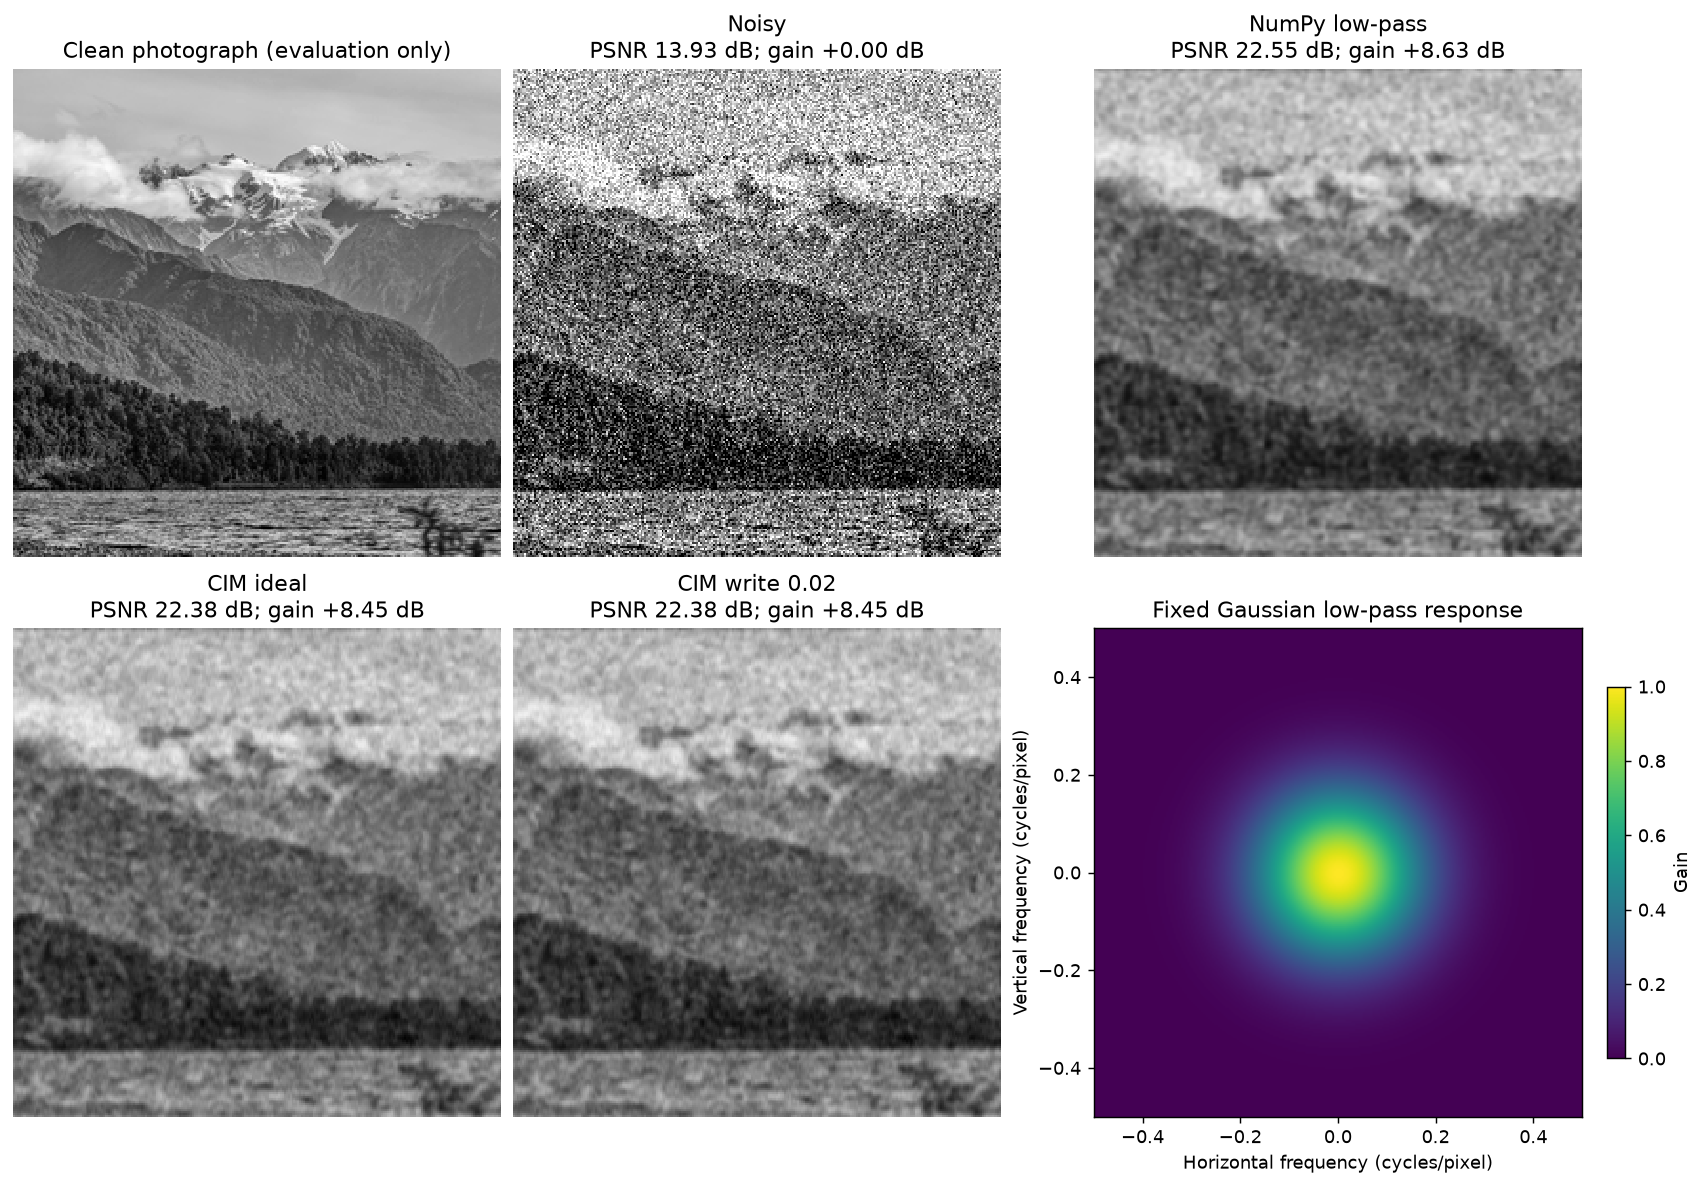

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(13, 9), dpi=130, constrained_layout=True)
panels = axes.ravel()
panels[0].imshow(clean, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
panels[0].set_title("Clean photograph (evaluation only)")
panels[0].axis("off")
for ax, (label, item) in zip(panels[1:5], results.items()):
    ax.imshow(item["image"], cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    gain = item["psnr_db"] - results["Noisy"]["psnr_db"]
    ax.set_title(f"{label}\nPSNR {item['psnr_db']:.2f} dB; gain {gain:+.2f} dB")
    ax.axis("off")
response = panels[5].imshow(
    np.fft.fftshift(mask), cmap="viridis", vmin=0, vmax=1, extent=(-0.5, 0.5, -0.5, 0.5)
)
panels[5].set_title("Fixed Gaussian low-pass response")
panels[5].set_xlabel("Horizontal frequency (cycles/pixel)")
panels[5].set_ylabel("Vertical frequency (cycles/pixel)")
fig.colorbar(response, ax=panels[5], shrink=0.75, label="Gain")

# Run from this notebook's directory or the repository root.
notebook_dir = Path.cwd()
if not (notebook_dir / "03_dft_image_denoising.ipynb").is_file():
    notebook_dir = notebook_dir / "examples" / "notebooks"
assert (notebook_dir / "03_dft_image_denoising.ipynb").is_file()
asset_dir = notebook_dir / "assets"
asset_dir.mkdir(exist_ok=True)
fig.savefig(asset_dir / "dft_image_denoising.png", dpi=160)
plt.show()

The same executed figure is also saved as a relative PNG asset for notebook viewers that omit rich outputs:

![Clean, noisy, NumPy and CIM reconstructions, with the fixed Gaussian frequency response](assets/dft_image_denoising.png)